In [2]:
import sys
import subprocess

# Downgrade to NumPy 1.x to fix the C-API mismatch with matplotlib
subprocess.check_call([sys.executable, "-m", "pip", "install", "numpy<2"])

print("NumPy downgraded successfully! Restart your kernel if needed.")

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
NumPy downgraded successfully! Restart your kernel if needed.


In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load dataset and clean redundant index column
df = pd.read_csv('Advertising.csv')
if 'Unnamed: 0' in df.columns:
  df = df.drop(columns=['Unnamed: 0'])

# Display basic dataset overview
print('Dataset Shape:', df.shape)
print('\nMissing Values:\n', df.isnull().sum())
print('\nDescriptive Statistics:\n', df.describe())

# Set seaborn styling for professional visuals
sns.set_theme(style='whitegrid')

Dataset Shape: (200, 4)

Missing Values:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Descriptive Statistics:
                TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   14.022500
std     85.854236   14.846809   21.778621    5.217457
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   10.375000
50%    149.750000   22.900000   25.750000   12.900000
75%    218.825000   36.525000   45.100000   17.400000
max    296.400000   49.600000  114.000000   27.000000


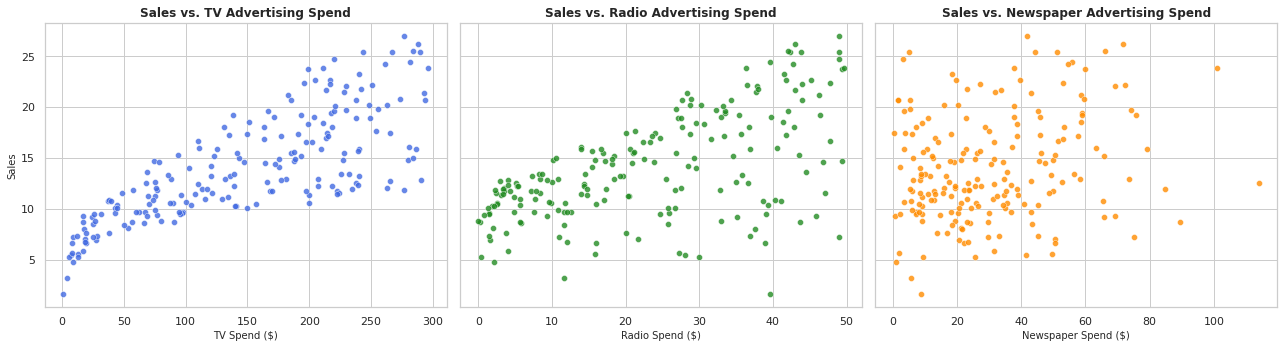

In [8]:
# 2. Individual Scatter Plots: Sales vs. Advertising Channels
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

sns.scatterplot(
    data=df, x='TV', y='Sales', ax=axes[0], color='royalblue', alpha=0.8
)
axes[0].set_title('Sales vs. TV Advertising Spend', fontsize=12, fontweight='bold')
axes[0].set_xlabel('TV Spend ($)', fontsize=10)
axes[0].set_ylabel('Sales', fontsize=10)

sns.scatterplot(
    data=df,
    x='Radio',
    y='Sales',
    ax=axes[1],
    color='forestgreen',
    alpha=0.8,
)
axes[1].set_title(
    'Sales vs. Radio Advertising Spend', fontsize=12, fontweight='bold'
)
axes[1].set_xlabel('Radio Spend ($)', fontsize=10)

sns.scatterplot(
    data=df,
    x='Newspaper',
    y='Sales',
    ax=axes[2],
    color='darkorange',
    alpha=0.8,
)
axes[2].set_title(
    'Sales vs. Newspaper Advertising Spend', fontsize=12, fontweight='bold'
)
axes[2].set_xlabel('Newspaper Spend ($)', fontsize=10)

plt.tight_layout()
plt.show()

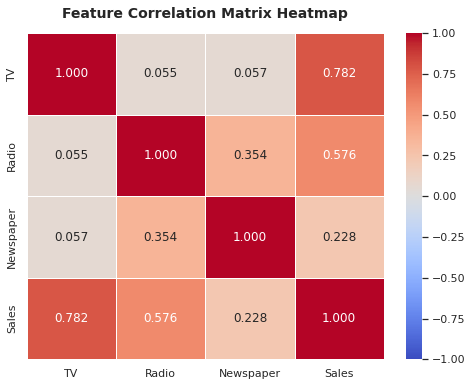

In [9]:
# 3. Correlation Matrix Heatmap
plt.figure(figsize=(8, 6))
correlation_matrix = df.corr()
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    linewidths=0.8,
    vmin=-1,
    vmax=1,
)
plt.title(
    'Feature Correlation Matrix Heatmap',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.show()

In [10]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 1. Define Features (X) and Target (y)
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# 2. Train/Test Split (80% train, 20% test with a fixed random seed for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Training set shape: {X_train.shape}')
print(f'Testing set shape: {X_test.shape}')

Training set shape: (160, 3)
Testing set shape: (40, 3)


In [13]:
# 3. Initialize and Train Linear Regression Baseline Model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 4. Make Predictions on Test Set
y_pred = lr_model.predict(X_test)

# 5. Evaluate Model Performance
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print('\n--- Baseline Model Performance ---')
print(f'R² Score: {r2:.4f}')
print(f'Root Mean Squared Error (RMSE): {rmse:.4f}')

# 6. Inspect Feature Coefficients (Business Impact / ROI Attribution)
coefficients = pd.DataFrame(
    lr_model.coef_, X.columns, columns=['Coefficient']
)
print('\n--- Feature Coefficients ---')
print(coefficients)
print(f'\nIntercept (Baseline Sales): {lr_model.intercept_:.4f}')


--- Baseline Model Performance ---
R² Score: 0.8994
Root Mean Squared Error (RMSE): 1.7816

--- Feature Coefficients ---
           Coefficient
TV            0.044730
Radio         0.189195
Newspaper     0.002761

Intercept (Baseline Sales): 2.9791


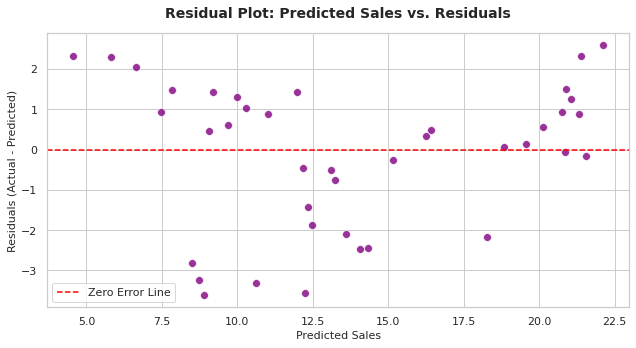

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals on the test set
residuals = y_test - y_pred

# Generate Residual Plot
plt.figure(figsize=(9, 5))
sns.scatterplot(x=y_pred, y=residuals, color='purple', alpha=0.8, s=60)
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5, label='Zero Error Line')

plt.title('Residual Plot: Predicted Sales vs. Residuals', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Sales', fontsize=11)
plt.ylabel('Residuals (Actual - Predicted)', fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

In [6]:
# Display basic dataset overview
print('Dataset Shape:', df.shape)
print('\nMissing Values:\n', df.isnull().sum())
print('\nDescriptive Statistics:\n', df.describe())

Dataset Shape: (200, 4)

Missing Values:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Descriptive Statistics:
                TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   14.022500
std     85.854236   14.846809   21.778621    5.217457
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   10.375000
50%    149.750000   22.900000   25.750000   12.900000
75%    218.825000   36.525000   45.100000   17.400000
max    296.400000   49.600000  114.000000   27.000000
